# North vs South zero-point offset

`Δm = m_DECaLS − m_north` for objects in both reductions, as a function of colour and magnitude.
Corrected north mag = `m_north + model(x)`. Sweeps have no i band, so colours are g−r, r−z, g−z.

In [114]:
import numpy as np, fitsio
import matplotlib.pyplot as plt
import scienceplots
from astropy.table import Table
plt.style.use(['science', 'grid', 'notebook'])

DATA = '/user/animesh.sah/DESI_PECVEL/'
BANDS = ['G', 'R', 'Z']

## 1. Matched overlap sample

In [115]:
LEG_COLS = ['BRICKID', 'OBJID', 'TYPE', 'RA', 'DEC'] + [f'{p}_{b}' for p in ('FLUX', 'MW_TRANSMISSION') for b in BANDS]

def load(kind, region, cols=None):
    return Table(fitsio.FITS(f'{DATA}TABLE_{kind}_{region}_v1_zerosep_all_features.fits')[1].read(columns=cols))

# zerosep tables = sweep rows whose RA/DEC are bit-identical to the DR1 target, rows aligned with DR1
DR1_COLS = ['TARGETID', 'PHOTSYS'] + [f'flux_{b.lower()}_dered' for b in BANDS]
dr_n, dr_s = load('DR1', 'north', DR1_COLS), load('DR1', 'south', DR1_COLS)
tid_n, tid_s = np.asarray(dr_n['TARGETID']), np.asarray(dr_s['TARGETID'])
leg_n, leg_s = load('legacy', 'north', LEG_COLS), load('legacy', 'south', LEG_COLS)

common, i_n, i_s = np.intersect1d(tid_n, tid_s, return_indices=True)
N, S, D = leg_n[i_n], leg_s[i_s], dr_n[i_n]      # D: the DR1 row of the same target

# identical flux in any band => the brick was only processed once and copied to both regions: not a real comparison
dup = np.any([np.asarray(N[f'FLUX_{b}']) == np.asarray(S[f'FLUX_{b}']) for b in BANDS], axis=0)
N, S, D = N[~dup], S[~dup], D[~dup]
print(f'targets in both regions: {len(common):,}   identical-flux duplicates dropped: {dup.sum():,}   kept: {len(N):,}')

targets in both regions: 37,763   identical-flux duplicates dropped: 7,267   kept: 30,496


In [116]:
def mag(t, b):
    # extinction-corrected AB mag; NaN where flux <= 0
    f = np.asarray(t[f'FLUX_{b}'], float) / np.asarray(t[f'MW_TRANSMISSION_{b}'], float)
    out = np.full(len(f), np.nan); ok = f > 0
    out[ok] = 22.5 - 2.5 * np.log10(f[ok])
    return out

def snmad(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))

mN = {b: mag(N, b) for b in BANDS}
mS = {b: mag(S, b) for b in BANDS}
dm = {b: mS[b] - mN[b] for b in BANDS}                    # DECaLS - north

# x-variables the offset may depend on. Built from the NORTH photometry by default, because that is
# what you have for the sample you want to correct (use mS to see the DECaLS-based version).
XSRC = mN
def variables(m, b):
    return {'g-r': m['G'] - m['R'], 'r-z': m['R'] - m['Z'], 'g-z': m['G'] - m['Z'],
            f'{b.lower()} mag': m[b]}

# range of the sample the correction will be applied to (0.5-99.5 percentile of table_match_final), drawn as green lines
TABLE = Table(fitsio.FITS(DATA + 'notebooks/table_match_final.fits')[1].read(columns=[f'{p}_{b}' for p in ('FLUX', 'MW_TRANSMISSION') for b in BANDS]))
mT = {b: mag(TABLE, b) for b in BANDS}
LIMITS = {}
for b in BANDS:
    for name, x in variables(mT, b).items():
        LIMITS[(b, name)] = np.nanpercentile(x, [0.5, 99.5])

## 2. Trends of Δm with colour and magnitude
Quantile bins; blue dashed = global median; green dashed = 0.5/99.5 percentile of `table_match_final.fits` (the sample to correct); χ²ν flat tests consistency with a constant.

Raw offset  DECaLS - north
 band  variable     slope [mag/unit]      chi2/dof flat   linear   sNMAD const -> linear
 G     g-r        -0.0541 +/- 0.0017       72.9     21.5     0.0422 -> 0.0395   all-pts slope -0.0518 +/- 0.0011 (91% kept)
 G     r-z        -0.1509 +/- 0.0043       66.5      2.8     0.0385 -> 0.0354   all-pts slope -0.1514 +/- 0.0029 (89% kept)
 G     g-z        -0.0505 +/- 0.0014       83.7     13.2     0.0388 -> 0.0352   all-pts slope -0.0480 +/- 0.0009 (89% kept)
 G     g mag      -0.0025 +/- 0.0004        4.5      2.6     0.0437 -> 0.0434   all-pts slope -0.0010 +/- 0.0003 (92% kept)
 R     g-r        -0.0260 +/- 0.0016       16.3      1.9     0.0370 -> 0.0359   all-pts slope -0.0264 +/- 0.0010 (90% kept)
 R     r-z        -0.1127 +/- 0.0040       43.1      1.8     0.0338 -> 0.0318   all-pts slope -0.1158 +/- 0.0026 (89% kept)
 R     g-z        -0.0296 +/- 0.0013       31.0      1.9     0.0338 -> 0.0322   all-pts slope -0.0310 +/- 0.0008 (89% kept)
 R     r mag    

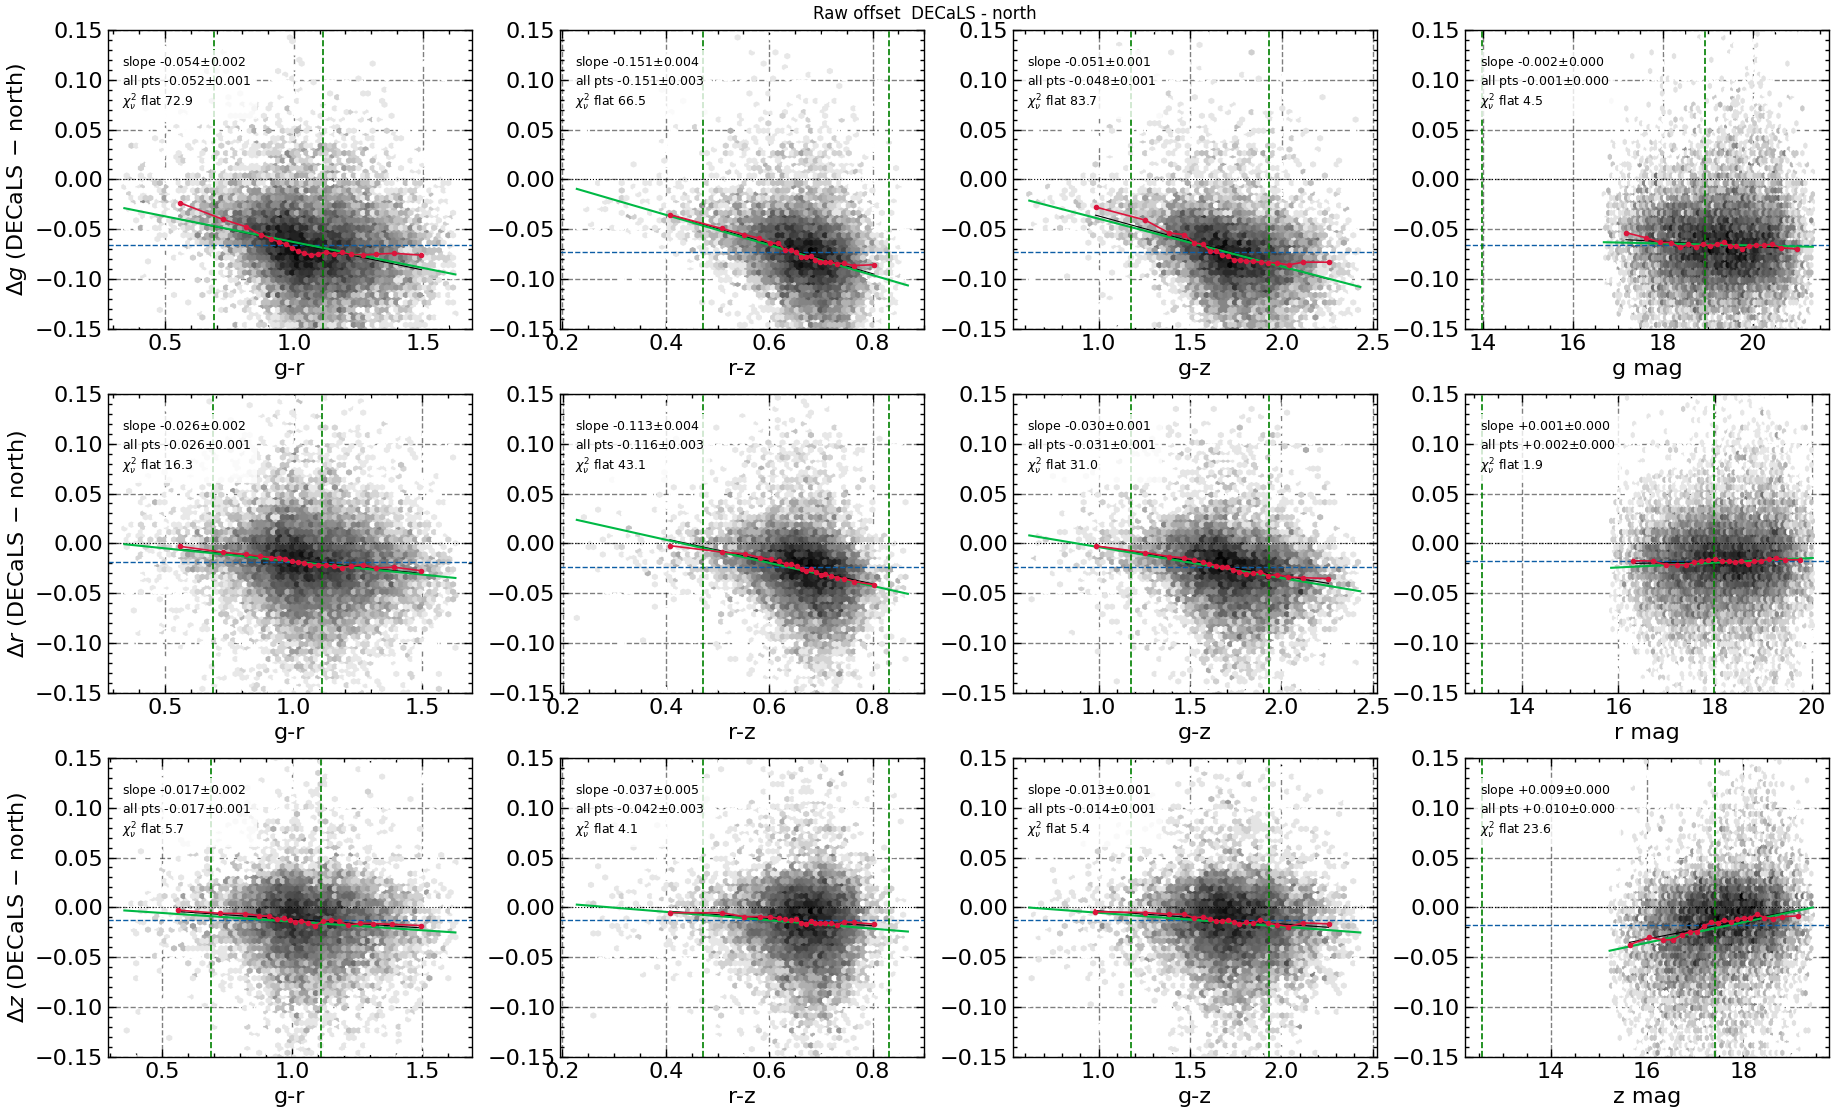

In [117]:
def binned(x, y, nbins=20, plo=1, phi=99):
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    lo, hi = np.percentile(x, [plo, phi])
    x, y = x[(x >= lo) & (x <= hi)], y[(x >= lo) & (x <= hi)]
    edges = np.quantile(x, np.linspace(0, 1, nbins + 1))
    idx = np.clip(np.searchsorted(edges, x, side='right') - 1, 0, nbins - 1)
    xc, med, err, n = (np.empty(nbins) for _ in range(4))
    for k in range(nbins):
        s = y[idx == k]
        xc[k], med[k], n[k] = np.median(x[idx == k]), np.median(s), len(s)
        err[k] = 1.253 * snmad(s) / np.sqrt(len(s))
    return x, y, xc, med, err

def fit_all(x, y, order=1, nsig=3, niter=5):
    # polynomial fit to every point (not binned), iteratively clipping |resid| > nsig * sNMAD
    x0 = np.median(x); keep = np.ones(len(x), bool)
    for _ in range(niter):
        p = np.polyfit(x[keep] - x0, y[keep], order)
        r = y - np.polyval(p, x - x0)
        keep = np.abs(r) < nsig * snmad(r[keep])
    s = snmad(r[keep])
    cov = s**2 * np.linalg.inv(np.vander(x[keep] - x0, order + 1).T @ np.vander(x[keep] - x0, order + 1))
    return p, x0, np.sqrt(cov[0, 0]), s, keep.mean()

def trend_stats(x, y, xc, med, err):
    w = 1 / err**2
    p, cov = np.polyfit(xc, med, 1, w=1 / err, cov='unscaled')
    m0 = np.average(med, weights=w)
    chi2_flat = np.sum(((med - m0) / err)**2) / (len(xc) - 1)
    chi2_lin = np.sum(((med - np.polyval(p, xc)) / err)**2) / (len(xc) - 2)
    return dict(slope=p[0], slope_err=np.sqrt(cov[0, 0]), chi2_flat=chi2_flat, chi2_lin=chi2_lin,
                s_const=snmad(y), s_lin=snmad(y - np.polyval(p, x)), p=p,
                all=fit_all(x, y))

def trend_grid(dmd, src, bands=BANDS, ylim=(-0.15, 0.15), title=''):
    # rows = bands, columns = variables. dmd[b] is the offset (raw or residual after a correction).
    ncol = len(variables(src, bands[0]))
    fig, axes = plt.subplots(len(bands), ncol, figsize=(4.6 * ncol, 3.8 * len(bands)), squeeze=False)
    print(f'{title}\n band  variable     slope [mag/unit]      chi2/dof flat   linear   sNMAD const -> linear')
    for r, b in enumerate(bands):
        for ax, (name, xv) in zip(axes[r], variables(src, b).items()):
            x, y, xc, med, err = binned(xv, dmd[b])
            st = trend_stats(x, y, xc, med, err)
            ax.hexbin(x, y, gridsize=70, extent=(x.min(), x.max(), *ylim), bins='log', cmap='Greys', mincnt=1)
            ax.axhline(0, color='k', ls=':', lw=0.8)
            ax.axhline(np.median(y), color='C0', ls='--', lw=1)
            ax.errorbar(xc, med, err, fmt='o-', color='crimson', ms=3, lw=1.2)
            ax.plot(xc, np.polyval(st['p'], xc), 'k-', lw=0.8, label='binned fit')
            pa, x0a, sa, _, _ = st['all']
            xx = np.array([x.min(), x.max()]); ax.plot(xx, np.polyval(pa, xx - x0a), color='C1', lw=1.5, label='all-points fit')
            ax.set_ylim(*ylim); ax.set_xlabel(name)
            for v in LIMITS[(b, name)]: ax.axvline(v, color='green', ls='--', lw=1.2)
            if ax is axes[r][0]: ax.set_ylabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)')
            ax.text(0.04, 0.92, f'slope {st["slope"]:+.3f}$\\pm${st["slope_err"]:.3f}\nall pts {pa[0]:+.3f}$\\pm${sa:.3f}\n$\\chi^2_\\nu$ flat {st["chi2_flat"]:.1f}',
                    transform=ax.transAxes, va='top', fontsize=9, bbox=dict(fc='w', ec='none', alpha=.8))
            print(f' {b:4s}  {name:9s}  {st["slope"]:+.4f} +/- {st["slope_err"]:.4f}   '
                  f'{st["chi2_flat"]:8.1f} {st["chi2_lin"]:8.1f}     {st["s_const"]:.4f} -> {st["s_lin"]:.4f}   '
                  f'all-pts slope {pa[0]:+.4f} +/- {sa:.4f} ({st["all"][4]:.0%} kept)')
    fig.suptitle(title); plt.tight_layout(); plt.show()

trend_grid(dm, XSRC, title='Raw offset  DECaLS - north')

## 3. Correct on one variable, test the others
Set `CHOICE[band] = (variable, polynomial order)`; variable is `'g-r'`, `'r-z'`, `'g-z'`, `'<band> mag'` or `None` (median only).
A trend that survives in the residual grid is independent of the variable you corrected on.
By default the fit uses the recipe of `selection_FP_individual.py --ctrans` (`FIT_RANGE = (0.7, 1.2)`, pivot 0.9954, x clipped to that range); set `FIT_RANGE = None` for a whole-range fit.


G: correcting on g-r (order 1), coefficients [-0.0797 -0.0663], x0=0.995
R: correcting on g-r (order 1), coefficients [-0.036  -0.0179], x0=0.995
Z: correcting on g-r (order 1), coefficients [-0.0232 -0.0123], x0=0.995
Residual after correction
 band  variable     slope [mag/unit]      chi2/dof flat   linear   sNMAD const -> linear
 G     g-r        +0.0026 +/- 0.0017       12.5     13.1     0.0391 -> 0.0391   all-pts slope +0.0016 +/- 0.0011 (91% kept)
 G     r-z        -0.0490 +/- 0.0043        8.9      2.1     0.0350 -> 0.0346   all-pts slope -0.0530 +/- 0.0028 (89% kept)
 G     g-z        -0.0089 +/- 0.0014        9.6      7.9     0.0350 -> 0.0349   all-pts slope -0.0084 +/- 0.0009 (89% kept)
 G     g mag      +0.0044 +/- 0.0004        9.0      1.6     0.0393 -> 0.0390   all-pts slope +0.0056 +/- 0.0002 (90% kept)
 R     g-r        -0.0008 +/- 0.0016        1.1      1.1     0.0359 -> 0.0359   all-pts slope -0.0031 +/- 0.0010 (90% kept)
 R     r-z        -0.0653 +/- 0.0041       14.

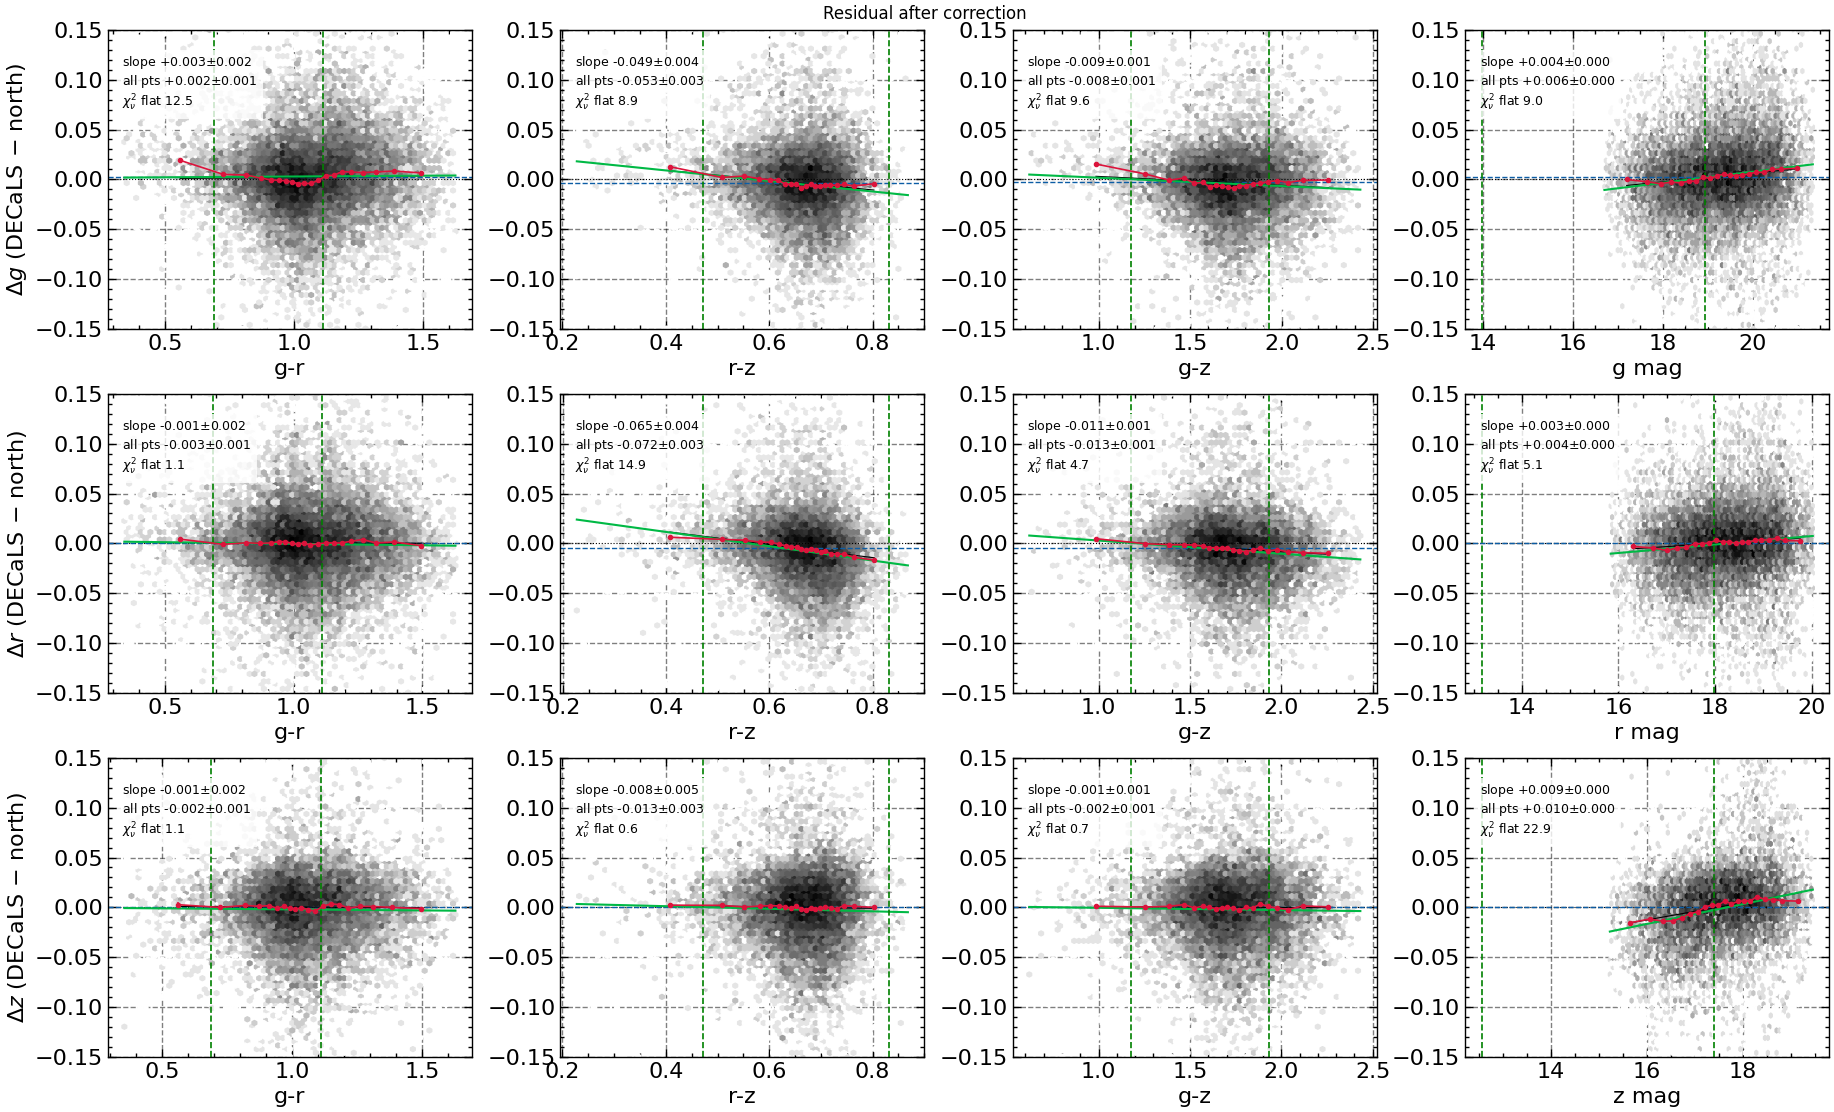

In [118]:
CHOICE = {'G': ('g-r', 1), 'R': ('g-r', 1), 'Z': ('g-r', 1)}      # <- edit and re-run this and the cells below

USE_ALL = False   # True: fit the correction to all points rather than the binned medians
# Fit recipe of count_objects.ipynb / selection_FP_individual.py --ctrans: uniform 0.05 bins (>50 objects), weighted fit
# restricted to FIT_RANGE of the x variable, pivoted at PIVOT. Set FIT_RANGE = None for the quantile-bin fit over the whole range.
FIT_RANGE, PIVOT = (0.7, 1.2), 0.9953964505060111

def binned_uniform(x, y, step=0.05, minn=50, span=(0, 2)):
    e = np.arange(span[0], span[1] + 1e-6, step); c = 0.5 * (e[:-1] + e[1:]); idx = np.digitize(x, e) - 1
    med, err = np.full(len(c), np.nan), np.full(len(c), np.nan)
    for k in range(len(c)):
        s = y[idx == k]
        if len(s) > minn: med[k], err[k] = np.median(s), 1.253 * snmad(s) / np.sqrt(len(s))
    return c, med, err

class Trend:
    # Δm(x) = poly(x - x0), x clipped to the fitted range (no extrapolation; = the --clip of the selection script).
    # Default: quantile-bin medians over the whole range. With fit_range: uniform bins inside fit_range, pivot at PIVOT.
    def __init__(self, x, y, order, use_all=USE_ALL, fit_range=FIT_RANGE):
        if fit_range is not None and order > 0:
            c, med, err = binned_uniform(x, y)
            f = np.isfinite(med) & (c > fit_range[0]) & (c < fit_range[1])
            self.x0, self.lo, self.hi = PIVOT, fit_range[0], fit_range[1]
            self.p = np.polyfit(c[f] - self.x0, med[f], order, w=1 / err[f])
            return
        xf, yf, xc, med, err = binned(x, y)
        self.x0, self.lo, self.hi = np.median(xf), xc.min(), xc.max()
        if use_all and order > 0:   # fit every point (sigma-clipped) instead of the binned medians
            self.p, self.x0 = fit_all(xf, yf, order)[:2]
        else:
            self.p = np.polyfit(xc - self.x0, med, order, w=1 / err) if order > 0 else [np.average(med, weights=1 / err**2)]
    def __call__(self, x):
        return np.polyval(self.p, np.clip(x, self.lo, self.hi) - self.x0)

models = {}
for b, (var, order) in CHOICE.items():
    x = variables(XSRC, b)[var] if var else None
    ok = np.isfinite(dm[b]) & (np.isfinite(x) if var else True)
    models[b] = (var, Trend(x[ok], dm[b][ok], order) if var else Trend(np.zeros(ok.sum()), dm[b][ok], 0))
    print(f'{b}: correcting on {var or "median only"} (order {order}), coefficients {np.round(models[b][1].p, 4)}, x0={models[b][1].x0:.3f}')

def residual(b):
    var, model = models[b]
    return dm[b] - (model(variables(XSRC, b)[var]) if var else model(np.zeros(len(N))))

dm_res = {b: residual(b) for b in BANDS}
trend_grid(dm_res, XSRC, title='Residual after correction')

## 4. Apply to the north sample

In [119]:
def correct_north(t):
    m = {b: mag(t, b) for b in BANDS}
    out = {}
    for b in BANDS:
        var, model = models[b]
        x = variables(m, b)[var] if var else np.zeros(len(t))
        out[b] = m[b] + model(x)
    return out

# sanity check on the overlap itself: corrected north vs DECaLS should be centred on 0
mc = correct_north(N)
for b in BANDS:
    d = (mS[b] - mc[b])[np.isfinite(mS[b] - mc[b])]
    print(f'{b}: median {np.median(d):+.4f}  sNMAD {snmad(d):.4f}')

G: median +0.0028  sNMAD 0.0395
R: median +0.0003  sNMAD 0.0362
Z: median +0.0000  sNMAD 0.0370


## 5. Zero-sep sample vs DR1: does the offset depend on where the target was selected?
Every overlap target is a DR1 target with a `PHOTSYS` (the region it was selected in). Its DR1 flux equals the sweep flux of
that region, so one of the two sweep rows is the "own" measurement and the other is the cross-region one. Because
targets are selected on their own-system photometry, the offset can be biased differently for the two subsets.

PHOTSYS=N: median DR1 flux / own-region sweep  G 1.0000  R 1.0000  Z 1.0000   / other-region sweep  G 0.9339  R 0.9777  Z 0.9877
PHOTSYS=S: median DR1 flux / own-region sweep  G 1.0000  R 1.0000  Z 1.0000   / other-region sweep  G 1.0543  R 1.0119  Z 1.0234

band  subset       N     median    sNMAD   offset at g-r=1   slope
 G    PHOTSYS=N  10,283  -0.0744   0.0397   -0.0706        -0.0687
 G    PHOTSYS=S  10,877  -0.0583   0.0420   -0.0565        -0.0377
 R    PHOTSYS=N  10,539  -0.0245   0.0348   -0.0225        -0.0356
 R    PHOTSYS=S  10,877  -0.0130   0.0367   -0.0119        -0.0148
 Z    PHOTSYS=N  10,090  -0.0135   0.0371   -0.0125        -0.0190
 Z    PHOTSYS=S   4,336  -0.0117   0.0363   -0.0109        -0.0126


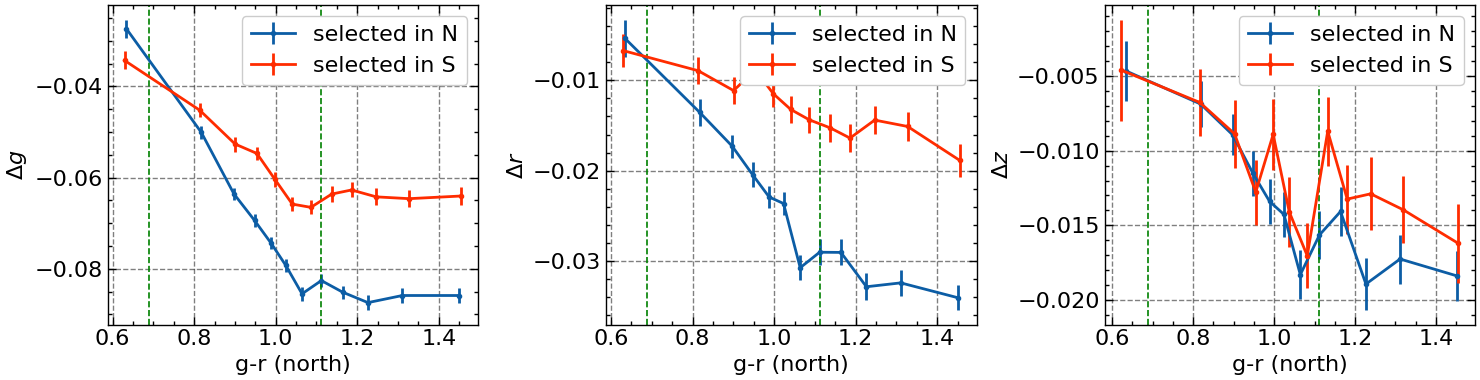

In [120]:
phot = np.char.strip(np.asarray(D['PHOTSYS']).astype(str))
fl = lambda t, b: np.asarray(t[f'FLUX_{b}'], float) / np.asarray(t[f'MW_TRANSMISSION_{b}'], float)

# DR1 flux should equal the sweep flux of the PHOTSYS region (ratio 1) and differ from the other region
def ratio(b, p, sweep):
    m = (phot == p) & (fl(sweep, b) > 0)
    return np.median(np.asarray(D[f'flux_{b.lower()}_dered'], float)[m] / fl(sweep, b)[m])
for p, own, oth in [('N', N, S), ('S', S, N)]:
    print(f'PHOTSYS={p}: median DR1 flux / own-region sweep  ' + '  '.join(f'{b} {ratio(b, p, own):.4f}' for b in BANDS)
          + '   / other-region sweep  ' + '  '.join(f'{b} {ratio(b, p, oth):.4f}' for b in BANDS))

gr = variables(XSRC, 'G')['g-r']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print('\nband  subset       N     median    sNMAD   offset at g-r=1   slope')
for ax, b in zip(axes, BANDS):
    for p, col in [('N', 'C0'), ('S', 'C3')]:
        m = (phot == p) & np.isfinite(dm[b]) & np.isfinite(gr)
        x, y, xc, med, err = binned(gr[m], dm[b][m], nbins=12)
        st = trend_stats(x, y, xc, med, err)
        ax.errorbar(xc, med, err, fmt='o-', ms=3, color=col, label=f'selected in {p}')
        print(f' {b:4s} PHOTSYS={p} {m.sum():7,}  {np.median(y):+.4f}   {snmad(y):.4f}   {np.polyval(st["p"], 1.0):+.4f}        {st["slope"]:+.4f}')
    for v in LIMITS[('G', 'g-r')]: ax.axvline(v, color='green', ls='--', lw=1.2)
    ax.set_xlabel('g-r (north)'); ax.set_ylabel(f'$\\Delta {b.lower()}$'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Comparison with the literature
Everything here is DECaLS − north (the literature quotes north − south, so their values are sign-flipped below).

band  cubic coefficients (x^3..x^0)                      value at g-z=1.59   Duncan+22   linear slope
 G    [ 0.0672 -0.2828  0.3187 -0.1304]   -0.0685          -0.056      -0.0505
 R    [ 0.0332 -0.1551  0.2026 -0.0839]   -0.0204          -0.012      -0.0296
 Z    [ 0.0274 -0.1287  0.1808 -0.0836]   -0.0112          +0.010      -0.0132


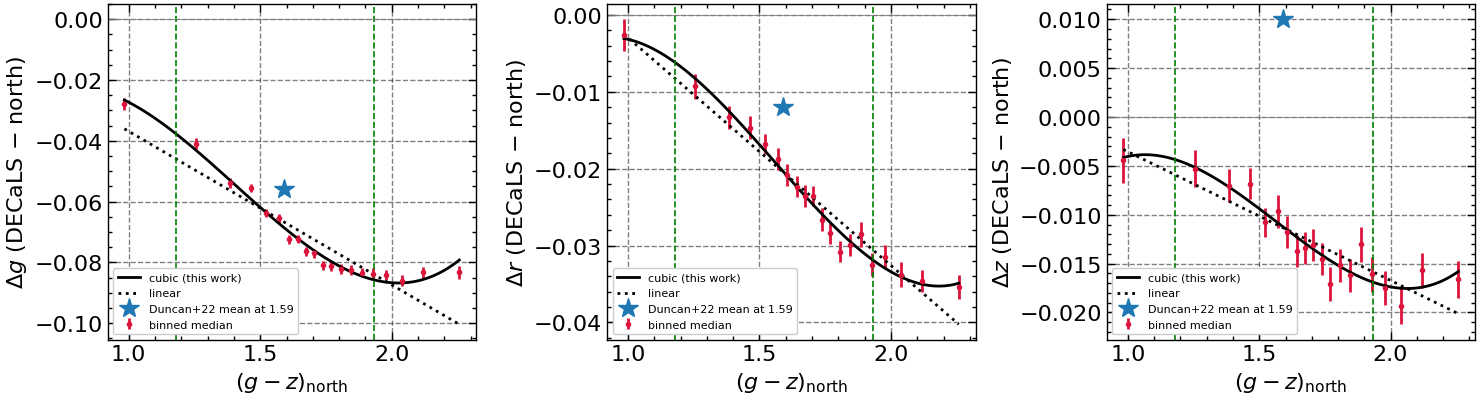

In [121]:
# (a) Duncan et al. 2022 (LS DR8): cubic in (g-z)_north; their mean offsets at (g-z)=1.59 are +0.056, +0.012, -0.010 (north - south)
DUNCAN_GZ, DUNCAN = 1.59, {'G': -0.056, 'R': -0.012, 'Z': +0.010}
def vlim(ax, name):     # green dashed = 0.5/99.5 percentile of table_match_final.fits in that colour
    for v in LIMITS[('G', name)]: ax.axvline(v, color='green', ls='--', lw=1.2)

gz = mN['G'] - mN['Z']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
print('band  cubic coefficients (x^3..x^0)                      value at g-z=1.59   Duncan+22   linear slope')
for ax, b in zip(axes, BANDS):
    x, y, xc, med, err = binned(gz, dm[b])
    p3, p1 = np.polyfit(xc, med, 3, w=1 / err), np.polyfit(xc, med, 1, w=1 / err)
    xs = np.linspace(xc.min(), xc.max(), 100)
    ax.errorbar(xc, med, err, fmt='o', color='crimson', ms=3, label='binned median')
    ax.plot(xs, np.polyval(p3, xs), 'k-', label='cubic (this work)')
    ax.plot(xs, np.polyval(p1, xs), 'k:', label='linear')
    ax.plot(DUNCAN_GZ, DUNCAN[b], '*', ms=15, color='tab:blue', label='Duncan+22 mean at 1.59')
    vlim(ax, 'g-z'); ax.axhline(0, color='grey', lw=0.6); ax.set_xlabel('$(g-z)_{\\rm north}$'); ax.set_ylabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)'); ax.legend(fontsize=8, loc='lower left')
    print(f' {b:4s} {np.round(p3, 4)}   {np.polyval(p3, DUNCAN_GZ):+.4f}          {DUNCAN[b]:+.3f}      {p1[0]:+.4f}')
plt.tight_layout(); plt.show()

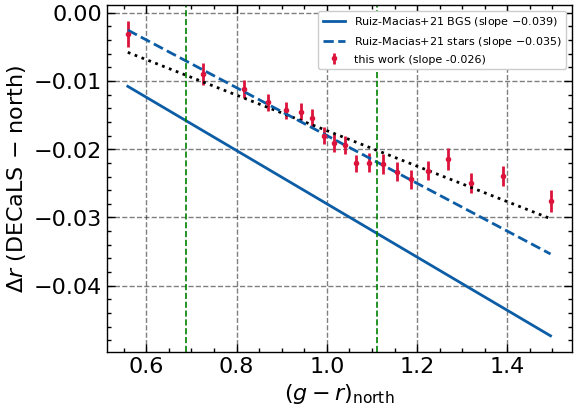

In [122]:
# (b) Ruiz-Macias et al. 2021 (DR9 BGS): r_DECaLS = r_BASS - 0.039 (g-r)_BASS + 0.011 (BGS objects), -0.035 (g-r) + 0.017 (stars)
gr = mN['G'] - mN['R']
x, y, xc, med, err = binned(gr, dm['R'])
p1 = np.polyfit(xc, med, 1, w=1 / err)
xs = np.linspace(xc.min(), xc.max(), 100)
plt.figure(figsize=(6, 4.5))
plt.errorbar(xc, med, err, fmt='o', color='crimson', ms=3, label=f'this work (slope {p1[0]:+.3f})')
plt.plot(xs, np.polyval(p1, xs), 'k:')
plt.plot(xs, -0.039 * xs + 0.011, 'C0-', label='Ruiz-Macias+21 BGS (slope $-$0.039)')
plt.plot(xs, -0.035 * xs + 0.017, 'C0--', label='Ruiz-Macias+21 stars (slope $-$0.035)')
vlim(plt.gca(), 'g-r'); plt.xlabel('$(g-r)_{\\rm north}$'); plt.ylabel('$\\Delta r$ (DECaLS $-$ north)'); plt.legend(fontsize=8); plt.show()

In [123]:
# (c) same sky region as Ruiz-Macias+21: 200 < RA < 240, 29 < DEC < 35
ra, dec = np.asarray(N['RA']), np.asarray(N['DEC'])
strip = (ra > 200) & (ra < 240) & (dec > 29) & (dec < 35)
print(f'objects in strip: {strip.sum():,} of {len(N):,}')
for lab, m in [('whole overlap', np.ones(len(N), bool)), ('RA 200-240, dec 29-35', strip)]:
    for b in BANDS:
        d = dm[b][m & np.isfinite(dm[b])]
        print(f'{lab:24s} {b}: N={len(d):6,}  median {np.median(d):+.4f}  sNMAD {snmad(d):.4f}')
    ok = m & np.isfinite(dm['R']) & np.isfinite(gr)
    x, y, xc, med, err = binned(gr[ok], dm['R'][ok], nbins=10)
    st = trend_stats(x, y, xc, med, err)
    print(f'{lab:24s} r vs g-r: slope {st["slope"]:+.4f} +/- {st["slope_err"]:.4f}   value at g-r=1.05 {np.polyval(st["p"], 1.05):+.4f}   (Ruiz-Macias: slope -0.039, value {-0.039*1.05+0.011:+.4f})')

objects in strip: 8,659 of 30,496
whole overlap            G: N=22,559  median -0.0656  sNMAD 0.0439
whole overlap            R: N=24,502  median -0.0182  sNMAD 0.0385
whole overlap            Z: N=19,065  median -0.0179  sNMAD 0.0449
whole overlap            r vs g-r: slope -0.0257 +/- 0.0016   value at g-r=1.05 -0.0187   (Ruiz-Macias: slope -0.039, value -0.0300)
RA 200-240, dec 29-35    G: N= 6,993  median -0.0716  sNMAD 0.0424
RA 200-240, dec 29-35    R: N= 8,343  median -0.0200  sNMAD 0.0384
RA 200-240, dec 29-35    Z: N= 5,222  median -0.0135  sNMAD 0.0370
RA 200-240, dec 29-35    r vs g-r: slope -0.0269 +/- 0.0028   value at g-r=1.05 -0.0210   (Ruiz-Macias: slope -0.039, value -0.0300)


### Duncan et al. 2022 curve vs this work, as a function of (g−z)
The cubic coefficients are not tabulated in the paper; they were read from the vector path of the dashed fit in its Fig. 1
(reproduces the paper's stated mean offsets at (g−z)=1.59: +0.056, +0.012, −0.010). Their offsets are north − south in asinh magnitudes for
bright (>10σ) point sources in LS DR8, colour-clipped to 0.3 < (g−z) < 3.3 (solid); dashed = beyond their clip. Sign flipped to DECaLS − north.

band   mean (mine - Duncan) over the overlap range of the data
 G     -0.0129   (range of difference -0.021 to +0.009)
 R     -0.0100   (range of difference -0.016 to +0.002)
 Z     -0.0236   (range of difference -0.031 to -0.013)


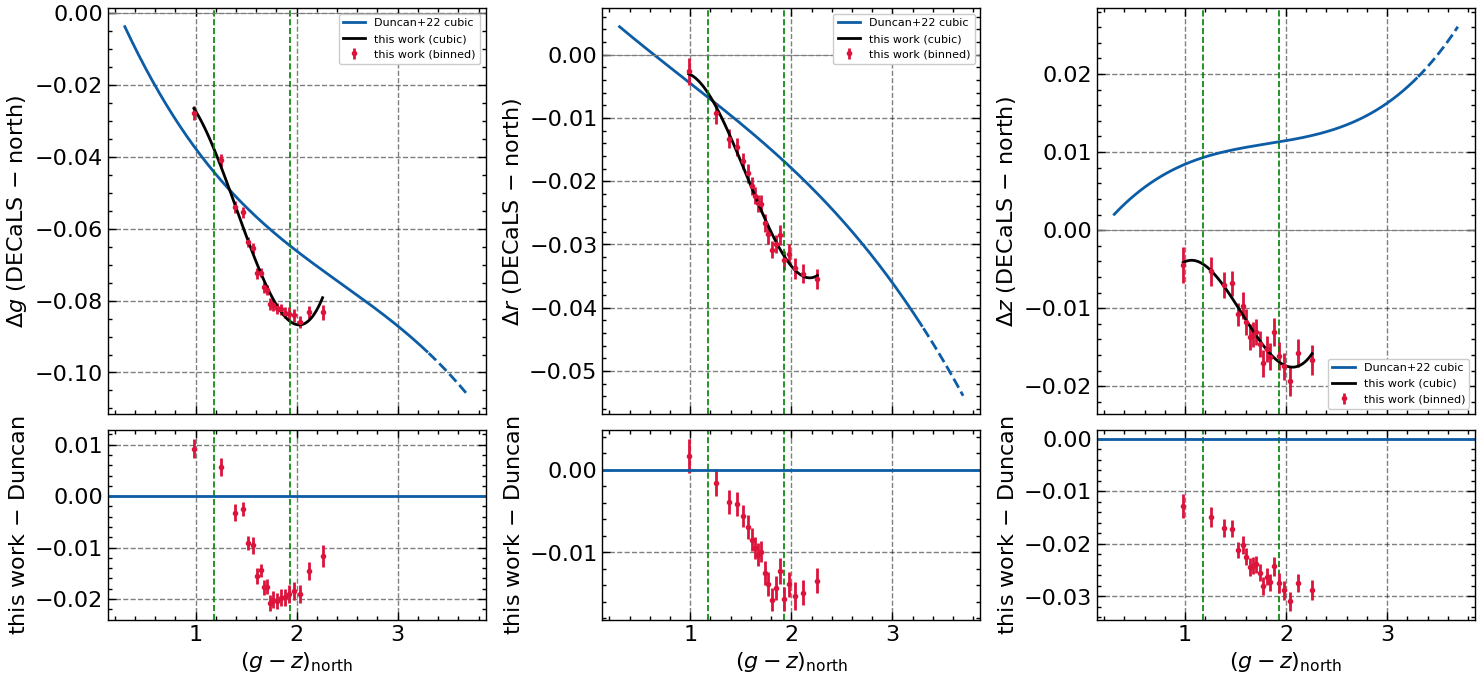

In [124]:
DUNCAN_CUBIC = {'G': [0.002918, -0.02133, 0.07205, -0.01591],      # north - south vs (g-z)_north, highest power first
                'R': [0.000737, -0.002062, 0.014419, -0.008557],
                'Z': [-0.00167, 0.009127, -0.018711, 0.002807]}
duncan = lambda b, x: -np.polyval(DUNCAN_CUBIC[b], x)                # DECaLS - north
xd = np.linspace(0.3, 3.7, 200); inside = xd <= 3.3

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex='col', gridspec_kw=dict(height_ratios=[3, 1.4]))
print('band   mean (mine - Duncan) over the overlap range of the data')
for k, b in enumerate(BANDS):
    x, y, xc, med, err = binned(gz, dm[b])
    p3 = np.polyfit(xc, med, 3, w=1 / err); xs = np.linspace(xc.min(), xc.max(), 100)
    ax = axes[0, k]
    ax.plot(xd[inside], duncan(b, xd[inside]), 'C0-', lw=2, label='Duncan+22 cubic')
    ax.plot(xd[~inside], duncan(b, xd[~inside]), 'C0--', lw=2)
    ax.errorbar(xc, med, err, fmt='o', color='crimson', ms=3, label='this work (binned)')
    ax.plot(xs, np.polyval(p3, xs), 'k-', label='this work (cubic)')
    vlim(ax, 'g-z'); vlim(axes[1, k], 'g-z')
    ax.axhline(0, color='grey', lw=0.6); ax.set_ylabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)'); ax.legend(fontsize=8)
    axes[1, k].errorbar(xc, med - duncan(b, xc), err, fmt='o', color='crimson', ms=3)
    axes[1, k].axhline(0, color='C0'); axes[1, k].set_xlabel('$(g-z)_{\\rm north}$'); axes[1, k].set_ylabel('this work $-$ Duncan')
    print(f' {b:4s}  {np.mean(med - duncan(b, xc)):+.4f}   (range of difference {np.min(med - duncan(b, xc)):+.3f} to {np.max(med - duncan(b, xc)):+.3f})')
plt.tight_layout(); plt.show()

## 7. Same trend in a pure sweep-to-sweep match (no DR1)
`matched_north_south.fits` pairs every north sweep object with its nearest south object within 0.35" (no DR1 involved). The pair selection and
cuts below are those of `north_south_match_photometry.ipynb` (galaxy TYPEs, grz observed, positive fluxes, MASKBITS, FRACMASKED/FRACIN/FRACFLUX,
one-to-one, `DEC >= 32.375`). Only bright pairs are used: `r_south < 18` is applied while reading, so the full 4.7M-pair table is never loaded. The DR1 overlap sample above is restricted to the same `DEC >= 32.375` for a fair comparison.
Offsets are DECaLS − north, and colours are the north ones, exactly as in the rest of this notebook.

In [125]:
MATCHED, DEC_MIN, ALLB = DATA + 'matched_north_south.fits', -30, ['G', 'R', 'Z', 'W1', 'W2']
per_side = (['BRICKID', 'OBJID', 'TYPE', 'MASKBITS'] + [f'FLUX_{b}' for b in ALLB] + [f'FLUX_IVAR_{b}' for b in ALLB]
            + [f'MW_TRANSMISSION_{b}' for b in BANDS] + [f'{p}_{b}' for p in ('NOBS', 'FRACMASKED', 'FRACIN', 'FRACFLUX') for b in BANDS])
RMAX = 18       # bright cut on the south r mag, applied at read time
h = fitsio.FITS(MATCHED)[1]
rows0 = np.flatnonzero(h.read_column('DEC') >= DEC_MIN)
k = h.read(columns=['BRICKID_S', 'OBJID_S', 'FLUX_R_S', 'MW_TRANSMISSION_R_S'], rows=rows0)
key = (k['BRICKID_S'].astype(np.int64) << 32) | k['OBJID_S'].astype(np.int64)
_, inv, cnt = np.unique(key, return_inverse=True, return_counts=True)       # one-to-one test on all pairs, before the bright cut
with np.errstate(divide='ignore', invalid='ignore'):
    bright = 22.5 - 2.5 * np.log10(k['FLUX_R_S'] / k['MW_TRANSMISSION_R_S']) < RMAX
sel = (cnt[inv] == 1) & bright
d = h.read(columns=['DEC'] + per_side + [c + '_S' for c in per_side], rows=rows0[sel])
del k, key, inv, cnt
side = lambda c, s: d[c + ('_S' if s == 'S' else '')]

def good(s):
    ok = np.isin(np.char.strip(side('TYPE', s).astype('U3')), ('REX', 'EXP', 'DEV', 'SER'))
    for b in BANDS:
        ok &= (side(f'NOBS_{b}', s) >= 1) & (side(f'FRACMASKED_{b}', s) < 0.4) & (side(f'FRACIN_{b}', s) > 0.2) & (side(f'FRACFLUX_{b}', s) < 5)
    for b in ALLB:
        ok &= (side(f'FLUX_{b}', s) > 0) & (side(f'FLUX_IVAR_{b}', s) > 0)
    return ok & ((side('MASKBITS', s) & ((1 << 1) | (1 << 12) | (1 << 13))) == 0)

valid = good('N') & good('S')
mag_side = lambda b, s: 22.5 - 2.5 * np.log10(side(f'FLUX_{b}', s)[valid] / side(f'MW_TRANSMISSION_{b}', s)[valid])
mNs, mSs = {b: mag_side(b, 'N') for b in BANDS}, {b: mag_side(b, 'S') for b in BANDS}
print(f'matched pairs with DEC >= {DEC_MIN}, one-to-one, r_S<{RMAX}: {len(d):,}   passing the quality cuts: {valid.sum():,}')
del d

matched pairs with DEC >= -30, one-to-one, r_S<18: 1,403,370   passing the quality cuts: 44,376


sample                                       N band   median   slope vs g-r   slope vs g-z   offset at g-r=1.0
DR1 zero-sep overlap, DEC>=32.375       22,559 G     -0.0656   -0.0541        -0.0505        -0.0641
DR1 zero-sep overlap, DEC>=32.375       24,502 R     -0.0182   -0.0260        -0.0296        -0.0173
DR1 zero-sep overlap, DEC>=32.375       19,065 Z     -0.0179   -0.0175        -0.0132        -0.0120
DR1 zero-sep overlap, all DEC           22,559 G     -0.0656   -0.0541        -0.0505        -0.0641
DR1 zero-sep overlap, all DEC           24,502 R     -0.0182   -0.0260        -0.0296        -0.0173
DR1 zero-sep overlap, all DEC           19,065 Z     -0.0179   -0.0175        -0.0132        -0.0120
sweep match, bright r_S<18              44,376 G     -0.0696   -0.1076        -0.0669        -0.0771
sweep match, bright r_S<18              44,376 R     -0.0286   -0.0612        -0.0378        -0.0338
sweep match, bright r_S<18              44,376 Z     -0.0262   -0.0429        -0.

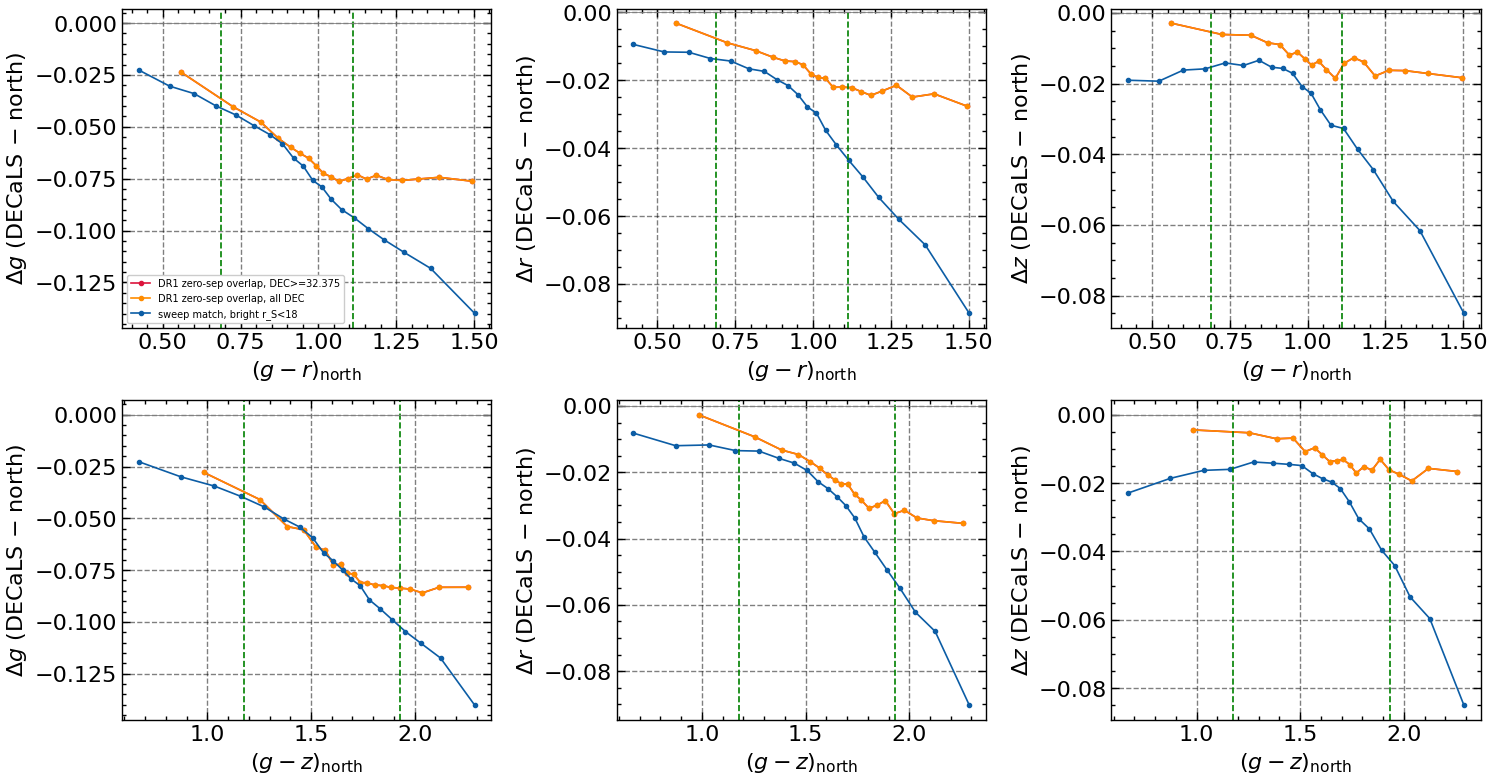

In [126]:
decN = np.asarray(N['DEC'])
SAMPLES = {   # label: (north mags, south mags, mask, colour)
    'DR1 zero-sep overlap, DEC>=32.375': (mN, mS, decN >= DEC_MIN, 'crimson'),
    'DR1 zero-sep overlap, all DEC':     (mN, mS, np.ones(len(N), bool), 'darkorange'),
    'sweep match, bright r_S<18':        (mNs, mSs, np.ones(valid.sum(), bool), 'C0'),     # r_S<18 already applied when loading
}
def fitline(x, y):
    xb, yb, xc, med, err = binned(x, y); st = trend_stats(xb, yb, xc, med, err); return st, (xc, med, err)

print(f'{"sample":36s} {"N":>9s} {"band":4s} {"median":>8s}   slope vs g-r   slope vs g-z   offset at g-r=1.0')
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for lab, (mn, ms, m, col) in SAMPLES.items():
    gr_, gz_ = (mn['G'] - mn['R'])[m], (mn['G'] - mn['Z'])[m]
    for k, b in enumerate(BANDS):
        y = (ms[b] - mn[b])[m]; ok = np.isfinite(y)
        st_r, (xc, med, err) = fitline(gr_[ok], y[ok]); axes[0, k].plot(xc, med, 'o-', color=col, ms=3, lw=1.2, label=lab if k == 0 else None)
        st_z, (xc, med, err) = fitline(gz_[ok], y[ok]); axes[1, k].plot(xc, med, 'o-', color=col, ms=3, lw=1.2)
        print(f'{lab:36s} {ok.sum():9,d} {b:4s} {np.median(y[ok]):+8.4f}   {st_r["slope"]:+.4f}        {st_z["slope"]:+.4f}        {np.polyval(st_r["p"], 1.0):+.4f}')
for k, b in enumerate(BANDS):
    for r, xl in enumerate(['$(g-r)_{\\rm north}$', '$(g-z)_{\\rm north}$']):
        vlim(axes[r, k], ['g-r', 'g-z'][r]); axes[r, k].set_xlabel(xl); axes[r, k].set_ylabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)'); axes[r, k].axhline(0, color='grey', lw=0.6)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Same comparison with g−r on the x axis
Duncan et al. is a function of (g−z), so to show it against g−r it is evaluated on each object's own (g−z)_north (clipped to 0.3–3.3 as in their correction)
and then binned in g−r, exactly like the data. Red = DR1 overlap, blue = bright sweep match (r_S < 18), blue dashed = Duncan evaluated on the DR1-overlap objects.

band   mean (DR1 overlap - Duncan-on-same-objects) over the data range
 G     -0.0126   (range -0.024 to +0.012)
 R     -0.0100   (range -0.015 to +0.002)
 Z     -0.0237   (range -0.030 to -0.011)


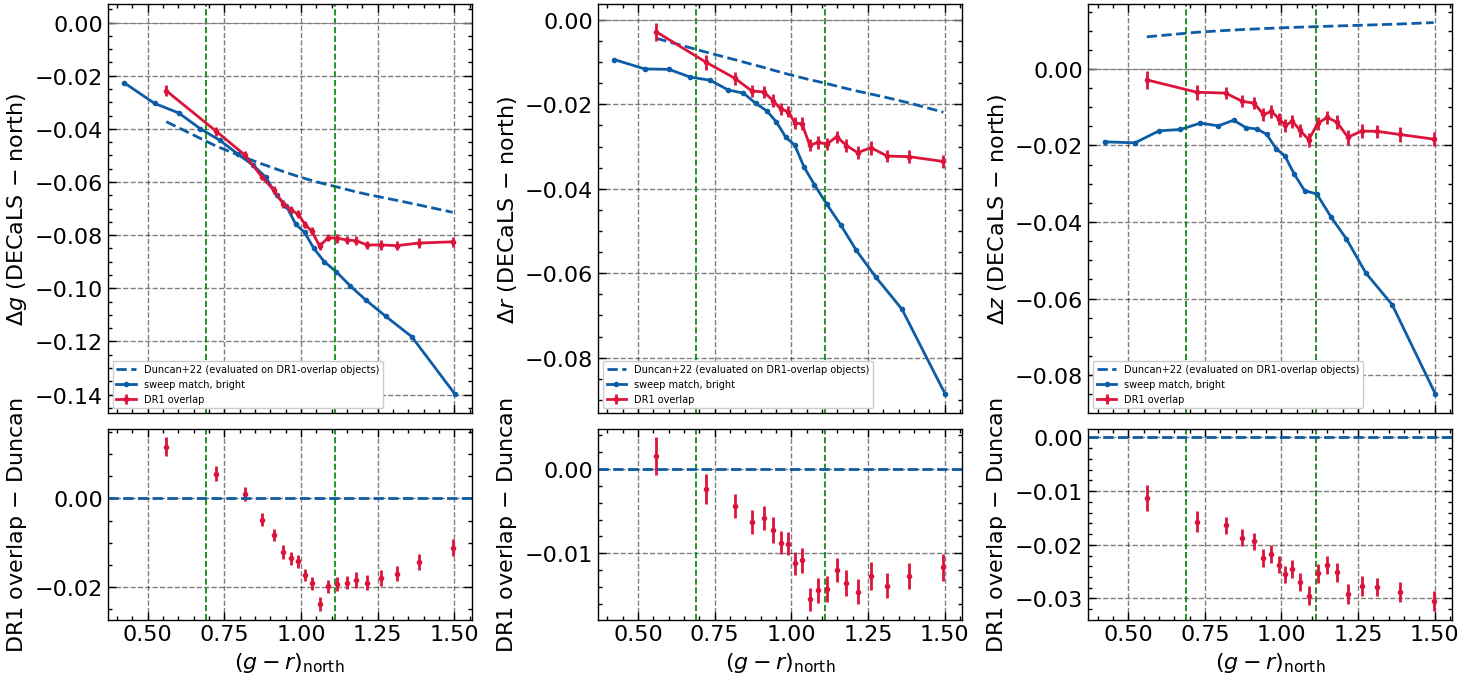

In [127]:
gr_dr1 = mN['G'] - mN['R']; gz_dr1 = np.clip(mN['G'] - mN['Z'], 0.3, 3.3)
gr_sw = mNs['G'] - mNs['R']
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex='col', gridspec_kw=dict(height_ratios=[3, 1.4]))
print('band   mean (DR1 overlap - Duncan-on-same-objects) over the data range')
for k, b in enumerate(BANDS):
    ok = np.isfinite(dm[b]) & np.isfinite(gr_dr1) & np.isfinite(gz_dr1)
    x, y, xc, med, err = binned(gr_dr1[ok], dm[b][ok])
    _, _, xd_, dmed, _ = binned(gr_dr1[ok], duncan(b, gz_dr1[ok]))          # Duncan prediction for the same objects, same bins
    ax = axes[0, k]
    ax.plot(xd_, dmed, 'C0--', lw=2, label='Duncan+22 (evaluated on DR1-overlap objects)')
    ax.errorbar(xc, med, err, fmt='o-', color='crimson', ms=3, label='DR1 overlap')
    y_sw = mSs[b] - mNs[b]
    _, _, xs_, smed, _ = binned(gr_sw, y_sw)
    ax.plot(xs_, smed, 'o-', color='C0', ms=3, label='sweep match, bright')
    vlim(ax, 'g-r'); vlim(axes[1, k], 'g-r')
    ax.axhline(0, color='grey', lw=0.6); ax.set_ylabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)'); ax.legend(fontsize=7)
    axes[1, k].errorbar(xc, med - dmed, err, fmt='o', color='crimson', ms=3); axes[1, k].axhline(0, color='C0', ls='--')
    axes[1, k].set_xlabel('$(g-r)_{\\rm north}$'); axes[1, k].set_ylabel('DR1 overlap $-$ Duncan')
    print(f' {b:4s}  {np.mean(med - dmed):+.4f}   (range {np.min(med - dmed):+.3f} to {np.max(med - dmed):+.3f})')
plt.tight_layout(); plt.show()

## 8. Constant offset: DR1 overlap vs the entire sweep match
No colour dependence here, just the distribution of `Δm = m_DECaLS − m_north` per band. Top row: histogram of Δm with the sample median marked. 
Bottom row: bootstrap distribution of the median (how well each sample pins down the constant offset).

sample                               band          N    median +/- (boot)    sNMAD
DR1 zero-sep overlap, all DEC        G        22,559   -0.0656     0.0003   0.0439
DR1 zero-sep overlap, DEC>=32.375    G        22,559   -0.0656     0.0003   0.0439
sweep match, bright r_S<18           G        44,376   -0.0696     0.0003   0.0530
DR1 zero-sep overlap, all DEC        R        24,502   -0.0182     0.0003   0.0385
DR1 zero-sep overlap, DEC>=32.375    R        24,502   -0.0182     0.0002   0.0385
sweep match, bright r_S<18           R        44,376   -0.0286     0.0002   0.0411
DR1 zero-sep overlap, all DEC        Z        19,065   -0.0179     0.0004   0.0449
DR1 zero-sep overlap, DEC>=32.375    Z        19,065   -0.0179     0.0004   0.0449


sweep match, bright r_S<18           Z        44,376   -0.0262     0.0003   0.0451


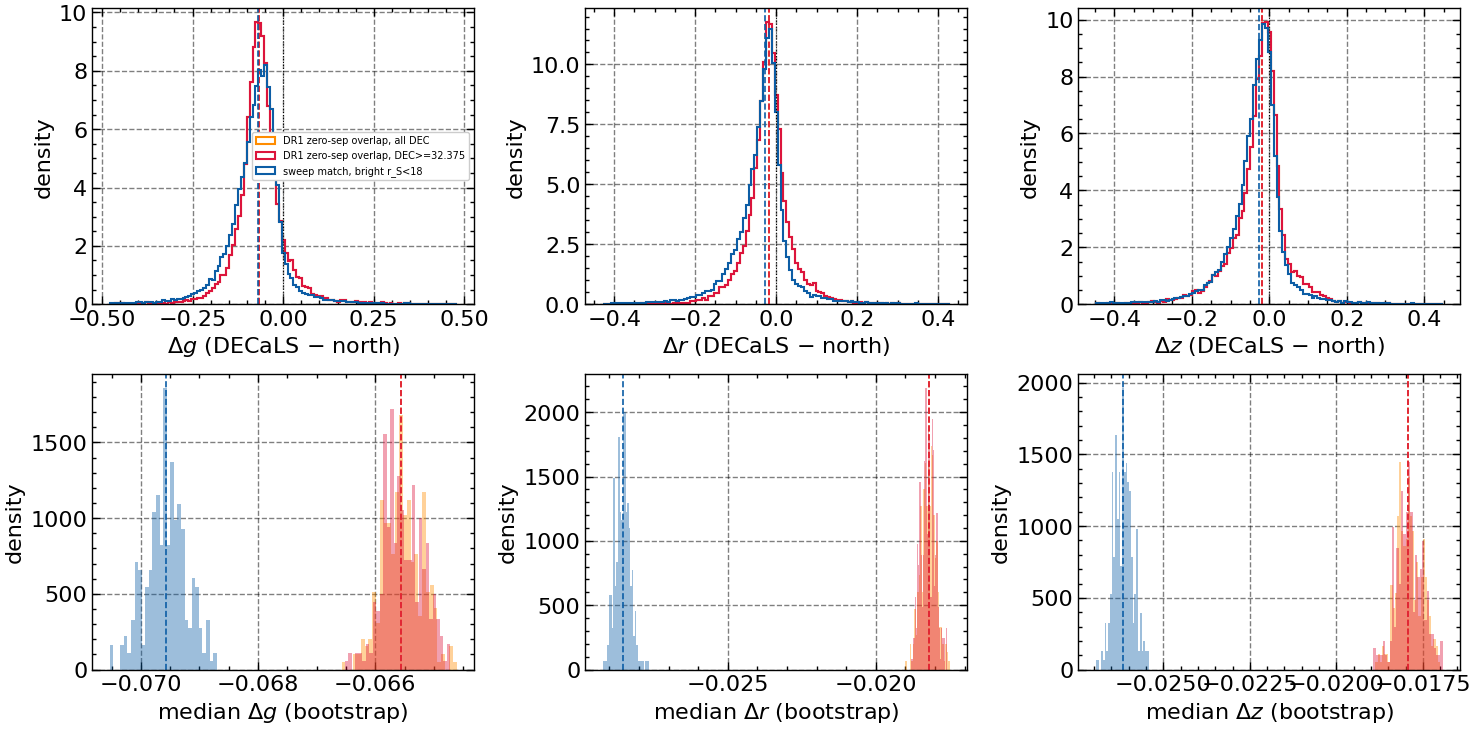

In [128]:
CONST = {k: SAMPLES[k] for k in ['DR1 zero-sep overlap, all DEC', 'DR1 zero-sep overlap, DEC>=32.375', 'sweep match, bright r_S<18']}
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
print(f'{"sample":36s} {"band":4s} {"N":>10s} {"median":>9s} {"+/- (boot)":>10s} {"sNMAD":>8s}')
for k, b in enumerate(BANDS):
    allY = {lab: (ms[b] - mn[b])[m] for lab, (mn, ms, m, col) in CONST.items()}
    allY = {lab: y[np.isfinite(y)] for lab, y in allY.items()}
    lim = np.percentile(np.concatenate(list(allY.values())), [0.5, 99.5]); lim = max(abs(lim[0]), abs(lim[1]), 0.1)
    for lab, (mn, ms, m, col) in CONST.items():
        y = allY[lab]; med = np.median(y)
        boot = np.array([np.median(rng.choice(y, len(y))) for _ in range(300)])
        axes[0, k].hist(y, bins=np.linspace(-lim, lim, 120), density=True, histtype='step', color=col, lw=1.5, label=lab if k == 0 else None)
        axes[0, k].axvline(med, color=col, ls='--', lw=1.2)
        axes[1, k].hist(boot, bins=30, density=True, histtype='stepfilled', alpha=0.4, color=col)
        axes[1, k].axvline(med, color=col, ls='--', lw=1.2)
        print(f'{lab:36s} {b:4s} {len(y):10,d} {med:+9.4f} {boot.std():10.4f} {snmad(y):8.4f}')
    axes[0, k].axvline(0, color='k', ls=':', lw=0.8)
    axes[0, k].set_xlabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)'); axes[0, k].set_ylabel('density')
    axes[1, k].set_xlabel(f'median $\\Delta {b.lower()}$ (bootstrap)'); axes[1, k].set_ylabel('density')
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()


## 9. Where the `--ctrans` values of `selection_FP_individual.py` come from
They are the last cell of `count_objects.ipynb`: a weighted linear fit to uniform 0.05-wide `(g−r)_north` bin medians (bins with >50 objects), 
**restricted to 0.7 < g−r < 1.2**, pivoted at g−r = 0.9954. Δ(g−r) is not linear, so the slope depends on the fitting range: 
the narrow range gives a steeper slope than a fit over the whole colour range (which is what sections 2–3 effectively do). 
Offsets at the pivot agree; only the slopes differ.

band  fit range     a (at pivot)   b [mag/mag]   bins     (script --ctrans: G -0.0663 -0.0798, R -0.0179 -0.0360, Z -0.0123 -0.0233)
 G    0.7-1.2      -0.0663        -0.0797     10
 G    0-2        -0.0637        -0.0534     28
 R    0.7-1.2      -0.0179        -0.0360     10
 R    0-2        -0.0173        -0.0249     28
 Z    0.7-1.2      -0.0123        -0.0232     10
 Z    0-2        -0.0120        -0.0155     27


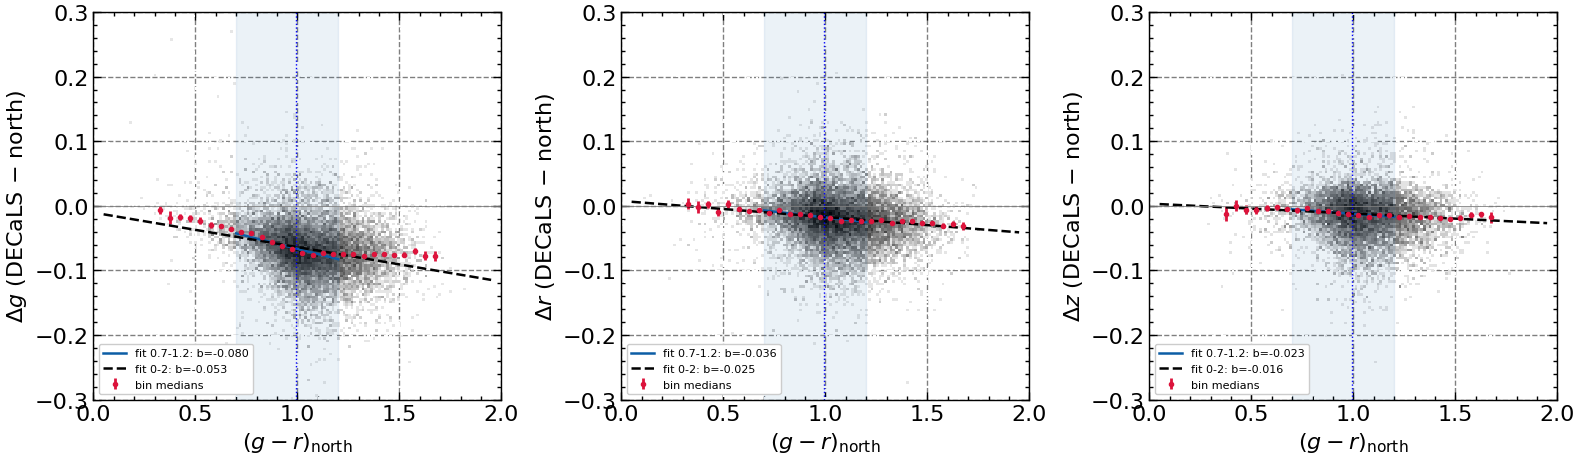

In [129]:
PIVOT, FIT_LO, FIT_HI = 0.9953964505060111, 0.7, 1.2      # as in count_objects.ipynb
grN = mN['G'] - mN['R']
edges = np.arange(0, 2.0001, 0.05); cen = 0.5 * (edges[:-1] + edges[1:])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
print('band  fit range     a (at pivot)   b [mag/mag]   bins     (script --ctrans: G -0.0663 -0.0798, R -0.0179 -0.0360, Z -0.0123 -0.0233)')
for ax, b in zip(axes, BANDS):
    ok = np.isfinite(dm[b]) & np.isfinite(grN)
    x, y = grN[ok], dm[b][ok]
    idx = np.digitize(x, edges) - 1
    med, err = np.full(len(cen), np.nan), np.full(len(cen), np.nan)
    for k in range(len(cen)):
        s = y[idx == k]
        if len(s) > 50: med[k], err[k] = np.median(s), 1.253 * snmad(s) / np.sqrt(len(s))
    ax.hist2d(x, y, bins=[np.linspace(0, 2, 150), np.linspace(-0.3, 0.3, 150)], norm=plt.matplotlib.colors.LogNorm(), cmap='Greys', cmin=1)
    ax.errorbar(cen, med, err, fmt='o', color='crimson', ms=3, label='bin medians')
    for lo, hi, col, ls in [(FIT_LO, FIT_HI, 'C0', '-'), (0, 2, 'k', '--')]:
        fit = np.isfinite(med) & (cen > lo) & (cen < hi)
        p = np.polyfit(cen[fit] - PIVOT, med[fit], 1, w=1 / err[fit])
        xs = np.linspace(max(lo, 0.05), min(hi, 1.95), 50)
        ax.plot(xs, np.polyval(p, xs - PIVOT), color=col, ls=ls, lw=1.8, label=f'fit {lo}-{hi}: b={p[0]:+.3f}')
        print(f' {b:4s} {lo}-{hi:<6}   {p[1]:+.4f}        {p[0]:+.4f}     {fit.sum()}')
    ax.axvspan(FIT_LO, FIT_HI, color='C0', alpha=0.08); ax.axvline(PIVOT, color='b', ls=':', lw=1)
    ax.axhline(0, color='grey', lw=0.6); ax.set_ylim(-0.3, 0.3); ax.set_xlim(0, 2)
    ax.set_xlabel('$(g-r)_{\\rm north}$'); ax.set_ylabel(f'$\\Delta {b.lower()}$ (DECaLS $-$ north)'); ax.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.show()


## 10. Residual trends after the section-3 correction, inside the fitted range
Residual = `Δm − model(g−r)`, i.e. DECaLS − corrected north. Restricted to objects with `FIT_RANGE[0] < (g−r)_north < FIT_RANGE[1]` (where the correction is not clipped), 
and shown against both g−r and r−z (green dashed = 0.5/99.5 percentile of the sample to correct). Quantile bins; orange = fit to all points (sigma-clipped).

Residual after correction, inside the fitted g-r range: objects with 0.7 < g-r < 1.2
 band  variable   slope [mag/mag]     chi2/dof flat   sNMAD   all-pts slope          offset (median)
 G     g-r     -0.0004 +/- 0.0035        5.8     0.0364   +0.0022 +/- 0.0025   +0.0000
 G     r-z     -0.0472 +/- 0.0070        4.7     0.0324   -0.0510 +/- 0.0047   -0.0053
 R     g-r     -0.0009 +/- 0.0033        0.6     0.0342   -0.0036 +/- 0.0023   +0.0001
 R     r-z     -0.0842 +/- 0.0065       12.4     0.0307   -0.0964 +/- 0.0044   -0.0050
 Z     g-r     -0.0004 +/- 0.0041        1.2     0.0353   -0.0054 +/- 0.0030   -0.0002
 Z     r-z     -0.0054 +/- 0.0076        1.0     0.0352   -0.0184 +/- 0.0054   -0.0001


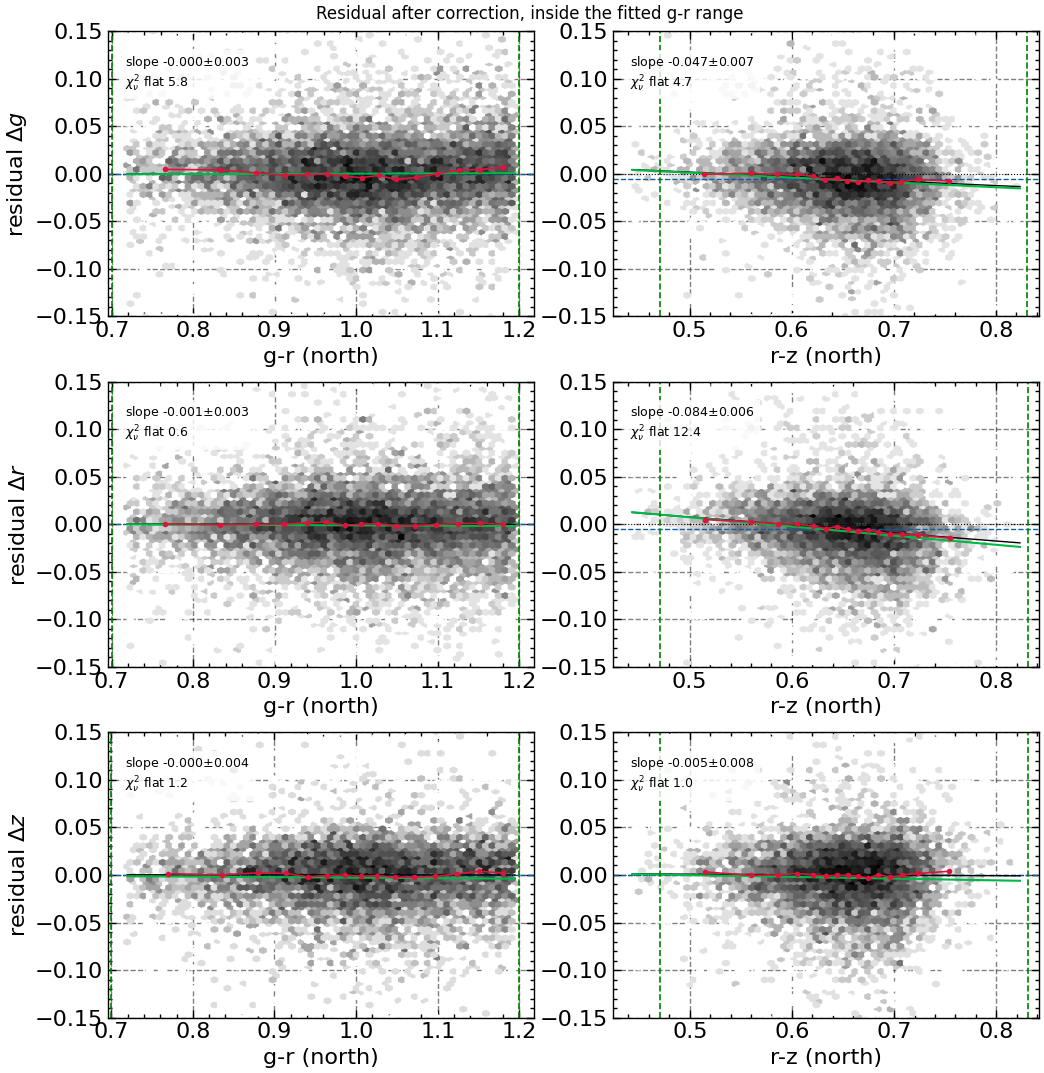

Raw offset (no correction), same g-r range: objects with 0.7 < g-r < 1.2
 band  variable   slope [mag/mag]     chi2/dof flat   sNMAD   all-pts slope          offset (median)
 G     g-r     -0.0798 +/- 0.0035       43.6     0.0385   -0.0776 +/- 0.0025   -0.0665
 G     r-z     -0.1498 +/- 0.0072       33.1     0.0350   -0.1501 +/- 0.0049   -0.0722
 R     g-r     -0.0370 +/- 0.0033        9.7     0.0351   -0.0396 +/- 0.0023   -0.0182
 R     r-z     -0.1290 +/- 0.0065       29.2     0.0317   -0.1388 +/- 0.0044   -0.0229
 Z     g-r     -0.0228 +/- 0.0041        3.4     0.0354   -0.0286 +/- 0.0030   -0.0125
 Z     r-z     -0.0354 +/- 0.0076        2.7     0.0352   -0.0458 +/- 0.0054   -0.0125


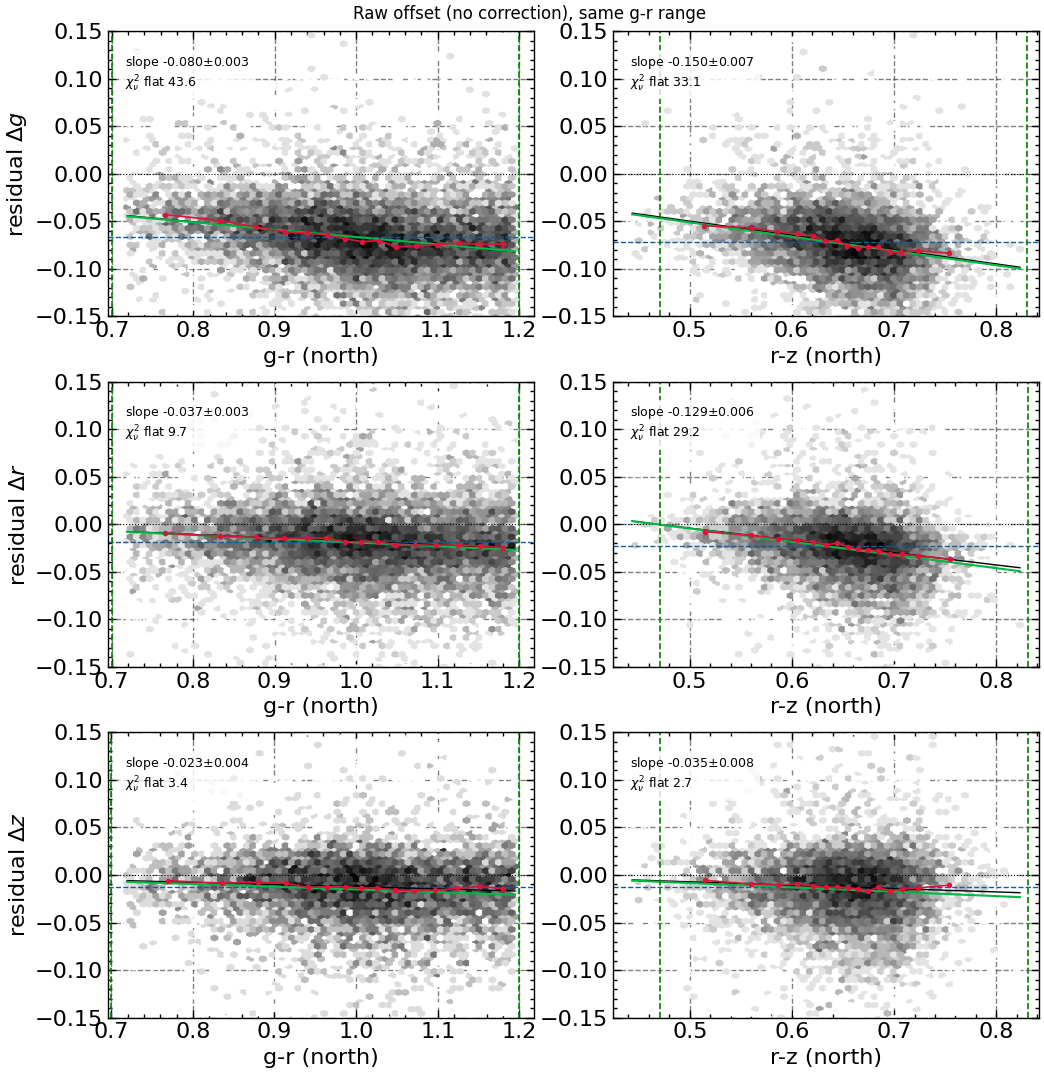

In [130]:
def residual_trends(res, lo, hi, title):
    grv, rzv = XSRC['G'] - XSRC['R'], XSRC['R'] - XSRC['Z']
    inr = (grv > lo) & (grv < hi)
    fig, axes = plt.subplots(3, 2, figsize=(10.5, 11))
    print(f'{title}: objects with {lo} < g-r < {hi}\n band  variable   slope [mag/mag]     chi2/dof flat   sNMAD   all-pts slope          offset (median)')
    for r, b in enumerate(BANDS):
        for ax, (name, xv, key) in zip(axes[r], [('g-r', grv, 'g-r'), ('r-z', rzv, 'r-z')]):
            m = inr & np.isfinite(res[b]) & np.isfinite(xv)
            x, y, xc, med, err = binned(xv[m], res[b][m], nbins=15)
            st = trend_stats(x, y, xc, med, err); pa, x0a, sa, _, _ = st['all']
            ax.hexbin(x, y, gridsize=60, extent=(x.min(), x.max(), -0.15, 0.15), bins='log', cmap='Greys', mincnt=1)
            ax.axhline(0, color='k', ls=':', lw=0.8); ax.axhline(np.median(y), color='C0', ls='--', lw=1)
            ax.errorbar(xc, med, err, fmt='o-', color='crimson', ms=3, lw=1.2)
            xx = np.array([x.min(), x.max()])
            ax.plot(xx, np.polyval(st['p'], xx), 'k-', lw=1)
            ax.plot(xx, np.polyval(pa, xx - x0a), color='C1', lw=1.5)
            if key == 'r-z':
                for v in LIMITS[('R', 'r-z')]: ax.axvline(v, color='green', ls='--', lw=1.2)
            else:
                for v in (lo, hi): ax.axvline(v, color='green', ls='--', lw=1.2)
            ax.set_ylim(-0.15, 0.15); ax.set_xlabel(f'{name} (north)')
            if ax is axes[r][0]: ax.set_ylabel(f'residual $\\Delta {b.lower()}$')
            ax.text(0.04, 0.92, f'slope {st["slope"]:+.3f}$\\pm${st["slope_err"]:.3f}\n$\\chi^2_\\nu$ flat {st["chi2_flat"]:.1f}', transform=ax.transAxes, va='top', fontsize=9, bbox=dict(fc='w', ec='none', alpha=.8))
            print(f' {b:4s}  {name:6s}  {st["slope"]:+.4f} +/- {st["slope_err"]:.4f}   {st["chi2_flat"]:8.1f}     {snmad(y):.4f}   {pa[0]:+.4f} +/- {sa:.4f}   {np.median(y):+.4f}')
    fig.suptitle(title); plt.tight_layout(); plt.show()

residual_trends(dm_res, *FIT_RANGE, title='Residual after correction, inside the fitted g-r range')
residual_trends(dm, *FIT_RANGE, title='Raw offset (no correction), same g-r range')


band   median before   median after   (0.7 < g-r < 1.2)
 G         -0.0663        +0.0001
 R         -0.0181        +0.0001
 Z         -0.0125        -0.0002


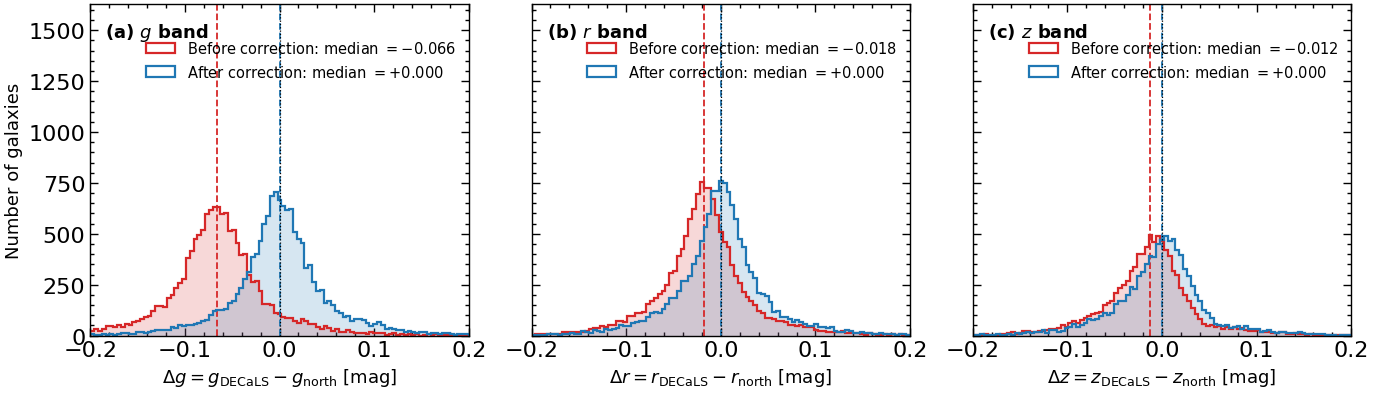

In [131]:
# Δm before and after the colour correction, objects inside the fitted g-r range
inr = (XSRC['G'] - XSRC['R'] > FIT_RANGE[0]) & (XSRC['G'] - XSRC['R'] < FIT_RANGE[1])
with plt.rc_context({'font.size': 12, 'axes.labelsize': 13, 'legend.fontsize': 10.5}):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
    bins = np.linspace(-0.2, 0.2, 100)
    print('band   median before   median after   (%.1f < g-r < %.1f)' % FIT_RANGE)
    for ax, b, tag in zip(axes, BANDS, 'abc'):
        raw, cor = [a[b][inr & np.isfinite(a[b])] for a in (dm, dm_res)]
        for y, col, lab in [(raw, '#d62728', 'Before correction'), (cor, '#1f77b4', 'After correction')]:
            ax.hist(y, bins=bins, histtype='stepfilled', color=col, alpha=0.18, lw=0)
            ax.hist(y, bins=bins, histtype='step', color=col, lw=1.6, label=f'{lab}: median $= {round(np.median(y), 3) + 0.0:+.3f}$')
            ax.axvline(np.median(y), color=col, ls='--', lw=1.3)
        ax.axvline(0, color='k', ls=':', lw=0.9)
        ax.set_xlim(-0.2, 0.2); ax.set_ylim(0, ax.get_ylim()[1] * 1.3)
        ax.set_xlabel(f'$\\Delta {b.lower()} = {b.lower()}_{{\\rm DECaLS}} - {b.lower()}_{{\\rm north}}$ [mag]')
        ax.text(0.04, 0.95, f'({tag}) ${b.lower()}$ band', transform=ax.transAxes, va='top', fontsize=13, fontweight='bold')
        ax.legend(loc='upper right', frameon=False, bbox_to_anchor=(1.0, 0.93))
        ax.tick_params(direction='in', top=True, right=True); ax.grid(False)
        print(f' {b:4s}      {np.median(raw):+.4f}        {np.median(cor):+.4f}')
    axes[0].set_ylabel('Number of galaxies')
    plt.tight_layout(); fig.savefig('zeropoint_offset_hist.pdf', bbox_inches='tight'); plt.show()


band  x      slope before        slope after         chi2/dof flat before -> after
 G    g-r    -0.0798 +/- 0.0035   -0.0004 +/- 0.0035        43.6 -> 5.8
 G    r-z    -0.1498 +/- 0.0072   -0.0472 +/- 0.0070        33.1 -> 4.7
 R    g-r    -0.0370 +/- 0.0033   -0.0009 +/- 0.0033         9.7 -> 0.6
 R    r-z    -0.1290 +/- 0.0065   -0.0842 +/- 0.0065        29.2 -> 12.4
 Z    g-r    -0.0228 +/- 0.0041   -0.0004 +/- 0.0041         3.4 -> 1.2
 Z    r-z    -0.0354 +/- 0.0076   -0.0054 +/- 0.0076         2.7 -> 1.0


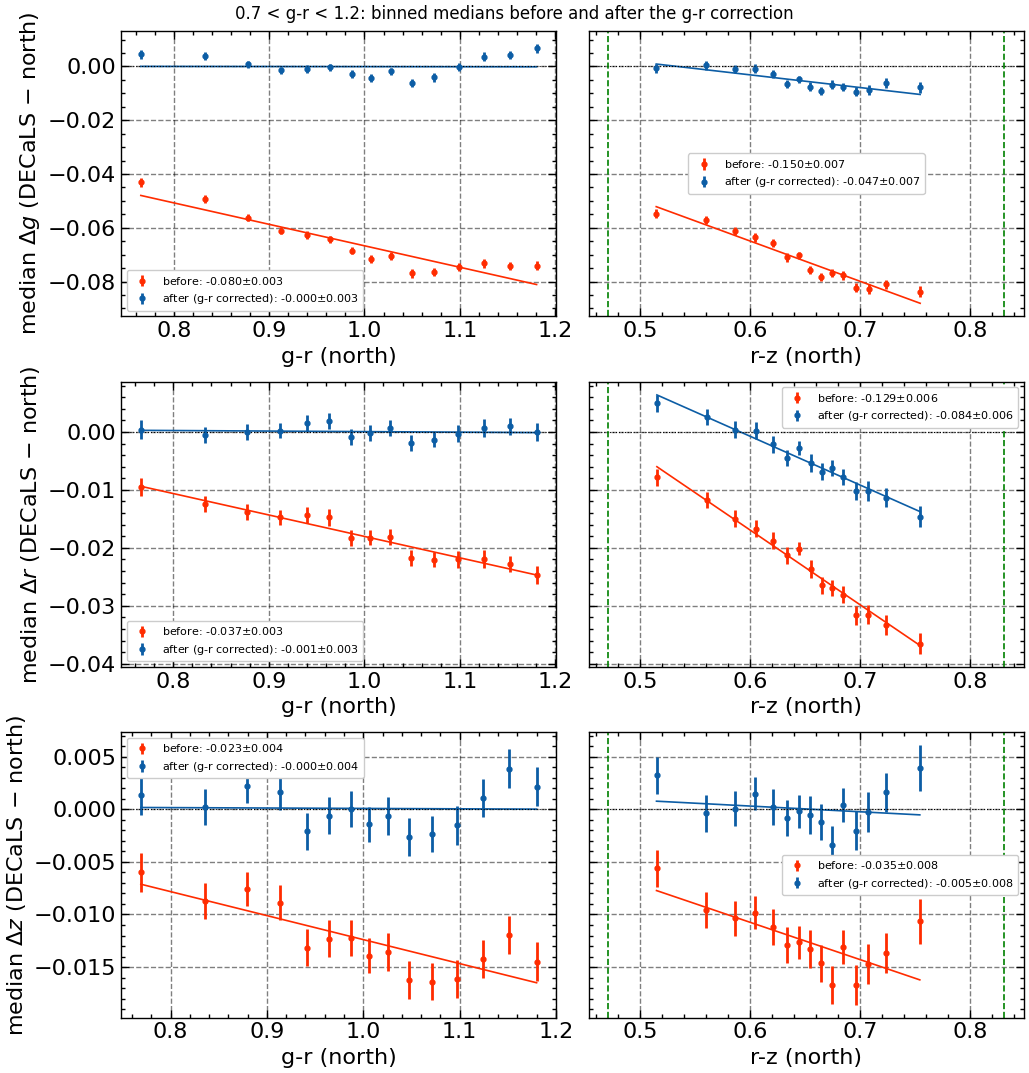

In [133]:
# before (raw) vs after (corrected on g-r) overlaid, against g-r and r-z, same g-r range
grv, rzv = XSRC['G'] - XSRC['R'], XSRC['R'] - XSRC['Z']
inr = (grv > FIT_RANGE[0]) & (grv < FIT_RANGE[1])
fig, axes = plt.subplots(3, 2, figsize=(10.5, 11), sharey='row')
print('band  x      slope before        slope after         chi2/dof flat before -> after')
for r, b in enumerate(BANDS):
    for ax, (name, xv) in zip(axes[r], [('g-r', grv), ('r-z', rzv)]):
        m = inr & np.isfinite(xv)
        for a, col, lab in [(dm, 'C3', 'before'), (dm_res, 'C0', 'after (g-r corrected)')]:
            mm = m & np.isfinite(a[b])
            x, y, xc, med, err = binned(xv[mm], a[b][mm], nbins=15)
            st = trend_stats(x, y, xc, med, err)
            ax.errorbar(xc, med, err, fmt='o', color=col, ms=3.5, label=f'{lab}: {st["slope"]:+.3f}$\\pm${st["slope_err"]:.3f}')
            ax.plot(xc, np.polyval(st['p'], xc), color=col, lw=1.2)
            if a is dm: s0 = st
            else: print(f' {b:4s} {name:5s}  {s0["slope"]:+.4f} +/- {s0["slope_err"]:.4f}   {st["slope"]:+.4f} +/- {st["slope_err"]:.4f}      {s0["chi2_flat"]:6.1f} -> {st["chi2_flat"]:.1f}')
        ax.axhline(0, color='k', ls=':', lw=0.8); ax.set_xlabel(f'{name} (north)'); ax.legend(fontsize=8, loc='best')
        if name == 'r-z':
            for v in LIMITS[('R', 'r-z')]: ax.axvline(v, color='green', ls='--', lw=1.2)
    axes[r][0].set_ylabel(f'median $\\Delta {b.lower()}$ (DECaLS $-$ north)')
fig.suptitle(f'{FIT_RANGE[0]} < g-r < {FIT_RANGE[1]}: binned medians before and after the g-r correction'); plt.tight_layout(); plt.show()
